# Before calling it three-point defense, test what carries forward

Joseph Smarrelli · September 2026

An opponent's early three-point percentage is an easy number to put in a scouting report. This study asks whether that number helps predict the attempts the team will face later, after accounting for who is shooting and where.

In the 2025-26 historical backtest, a shooter-and-location baseline performed better than carrying forward each defense's early opponent percentage. Across **54,257 later attempts**, log loss was **0.65125 for the baseline** and **0.65344 for the early-percentage shortcut**. Lower is better. The estimated improvement was 0.00219, with a 95% game-cluster interval of 0.00173 to 0.00269.

The practical recommendation is to show an opponent's three-point rate beside the shooters and locations it allowed. A low percentage by itself is weak evidence for a repeatable defensive advantage in this test.



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import three_point_defense
summary = three_point_defense.run()
summary

{'development_games': 1230,
 'test_games': 1230,
 'test_early_attempts': 36663,
 'test_late_attempts': 54257,
 'excluded_test_heaves': 50,
 'selected_C': np.float64(0.1),
 'selected_offset_prior_attempts': np.float64(1000000000.0),
 'raw_repeatability_r': np.float64(-0.08283749946252561),
 'residual_repeatability_r': np.float64(-0.09736989095484049),
 'context_vs_league_loss': {'difference': -0.0017565163386088567,
  'lower': -0.00220196754833071,
  'upper': -0.0013503355707248973},
 'offset_vs_context_loss': {'difference': 8.971846048556224e-11,
  'lower': -2.19580898406627e-10,
  'upper': 4.1000005572599897e-10},
 'raw_early_vs_context_loss': {'difference': 0.0021863202665234776,
  'lower': 0.001727666036624335,
  'upper': 0.0026862804687519727}}

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/defense_validation.csv')

,model,log_loss,brier,attempts
0,Prior-season league rate,0.653009,0.230200,54257
1,Early opponent percentage,0.653439,0.230399,54257
2,Shot-context baseline,0.651253,0.229395,54257
3,Baseline + early team residual,0.651253,0.229395,54257


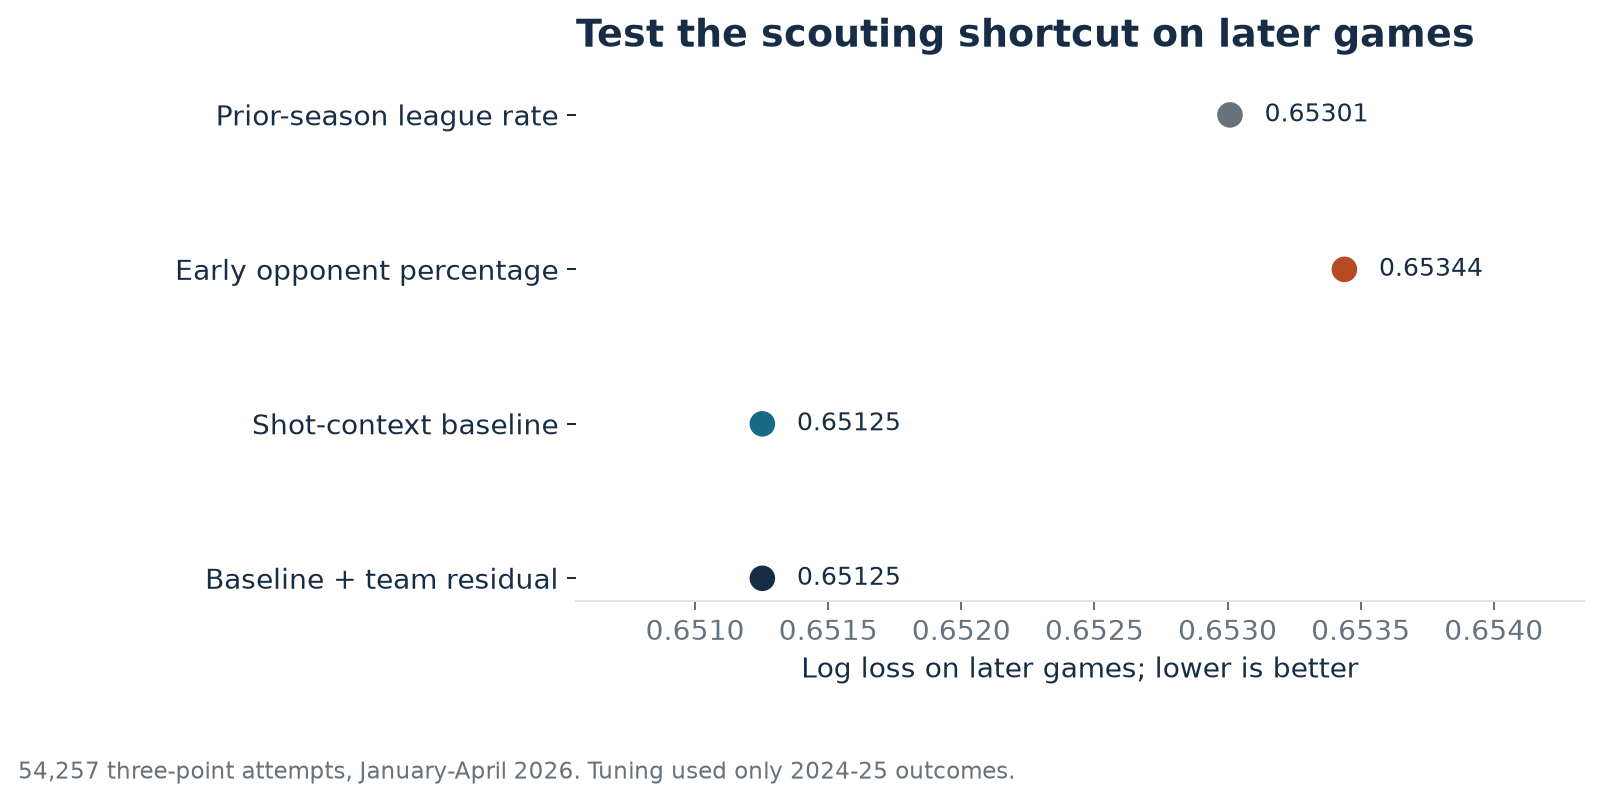

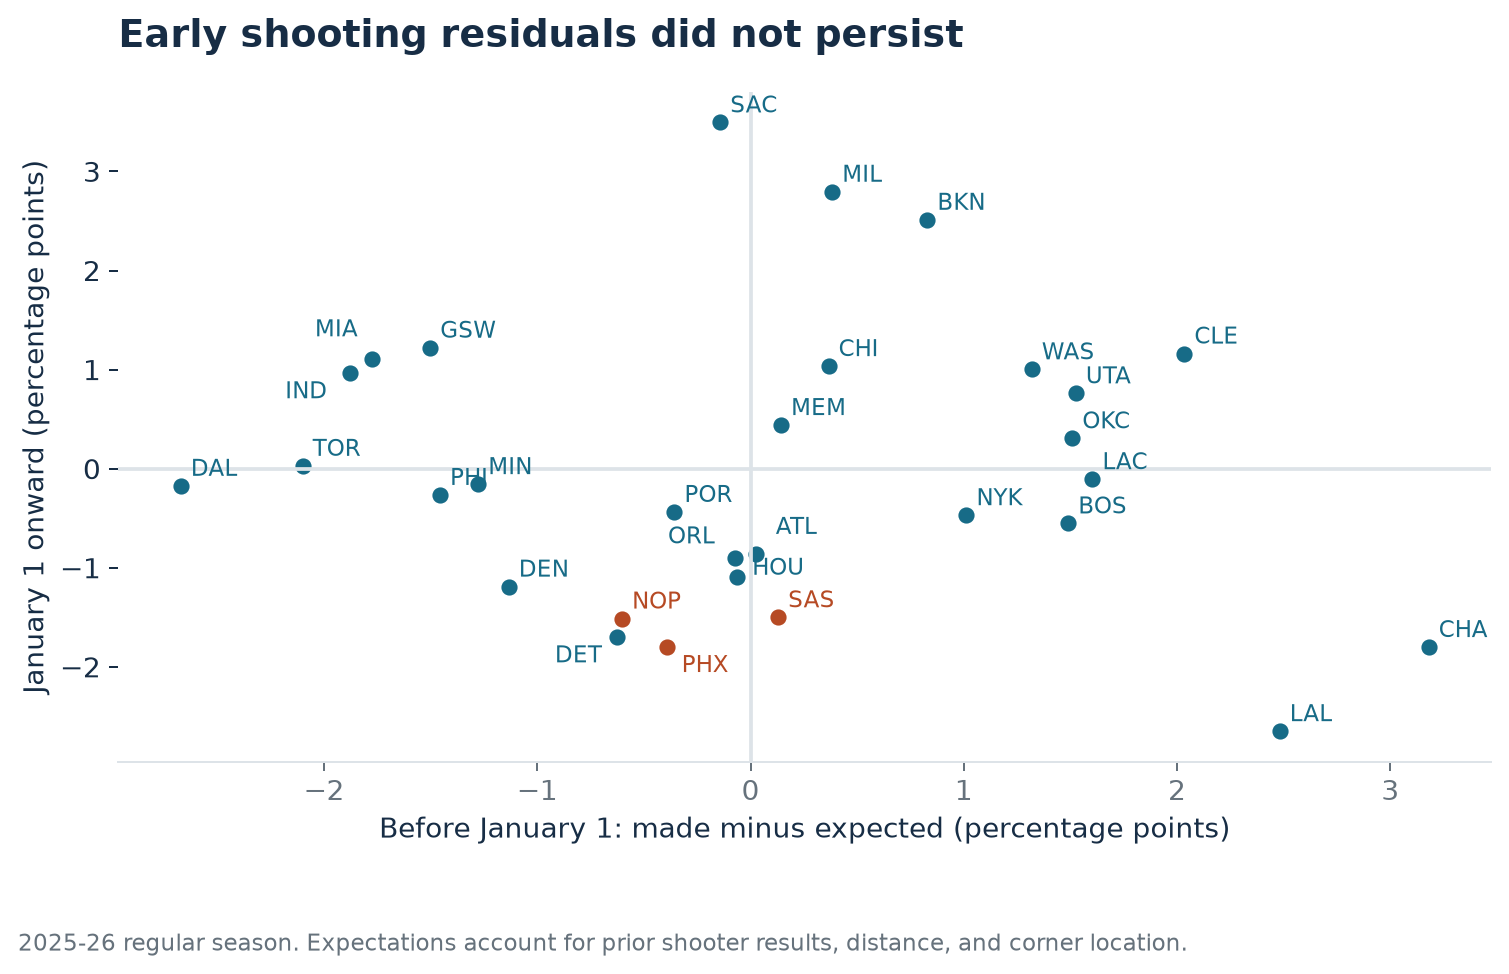

In [3]:
display(Image(filename='figures/defense_validation.png'))
display(Image(filename='figures/defense_repeatability.png'))

## Inspect all candidate settings and the requested teams

In [4]:
display(pd.read_csv('results/defense_tuning.csv').head(8))
teams = pd.read_csv('results/defense_teams.csv')
teams[teams.team.isin(['PHX', 'SAS', 'NOP'])]

,C,offset_prior_attempts,validation_logloss
0,0.10,1.000000e+09,0.653721
1,1.00,1.000000e+09,0.653752
2,0.01,1.000000e+09,0.653757
3,10.00,1.000000e+09,0.653763
4,0.10,2.000000e+03,0.653787
5,1.00,2.000000e+03,0.653819
6,0.01,2.000000e+03,0.653822
7,10.00,2.000000e+03,0.653830


,team,early_attempts,late_attempts,early_observed,late_observed,early_expected,late_expected,early_residual,late_residual,late_residual_low,late_residual_high,early_corner_share,late_corner_share
18,NOP,1462,1860,0.357729,0.344624,0.363752,0.359747,-0.006023,-0.015124,-0.035971,0.005878,0.276334,0.265054
23,PHX,1163,1710,0.355116,0.341520,0.359048,0.359517,-0.003932,-0.017997,-0.034370,-0.000013,0.256234,0.304094
26,SAS,1206,1821,0.361526,0.345964,0.360229,0.360961,0.001296,-0.014997,-0.031993,0.000348,0.268657,0.278418


In [5]:
pd.read_csv('results/defense_monitoring.csv')

,month,attempts,expected,observed,residual,review_required
0,2026-01,17199,0.359591,0.356590,-3.000814e-03,False
1,2026-02,12346,0.359274,0.357363,-1.911054e-03,False
2,2026-03,17601,0.359241,0.359241,-2.396844e-07,False
3,2026-04,7111,0.358984,0.369006,1.002164e-02,False


## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.